# News Topic Classifier Using BERT

### 🎯 Problem Statement & Objective
The goal of this project is to build an automated system that can categorize news headlines into four distinct topics: **World, Sports, Business, and Sci/Tech**. 

**Objective:**
* Fine-tune a pre-trained `bert-base-uncased` model using the Hugging Face Transformers library.
* Preprocess the **AG News Dataset** for optimal model performance.
* Evaluate the model using Accuracy and F1-score.
* Deploy the final model as an interactive application.

In [ ]:
# Install necessary libraries if running in Colab
!pip install transformers datasets torch scikit-learn accelerate

In [ ]:
import torch
import numpy as np
from datasets import load_dataset
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, f1_score


# Check for GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

## 1. Dataset Loading & Preprocessing
In this section, we load the **AG News Dataset** from the Hugging Face hub. 

**Preprocessing Steps:**
* **Tokenization:** Converting raw text into BERT-compatible tokens.
* **Padding & Truncation:** Setting a fixed `max_length` of 128 to ensure consistent input tensor shapes.
* **Format Conversion:** Converting the dataset into PyTorch tensors for model training.

In [ ]:
from datasets import load_dataset

dataset = load_dataset("ag_news")

train_data = dataset["train"]
test_data = dataset["test"]

### Tokenization & Preprocessing

In [ ]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

def tokenize(batch):
    return tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

encoded_dataset = dataset.map(tokenize, batched=True)
encoded_dataset.set_format("torch", columns=["input_ids", "attention_mask", "label"])

## 2. Model Development & Training
We utilize **Transfer Learning** by initializing the `BertForSequenceClassification` model with pre-trained weights from `bert-base-uncased`. 

**Training Configuration:**
* **Learning Rate:** 2e-5.
* **Batch Size:** 16.
* **Epochs:** 2.
* **Weight Decay:** 0.01 to help prevent overfitting.

In [ ]:
from transformers import BertForSequenceClassification

model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=4
)

### Training Setup

In [ ]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_dir="./logs",
    save_total_limit=2
)

## 3. Evaluation Metrics
To measure success, we use two primary metrics:
1. **Accuracy:** The percentage of total headlines correctly classified.

2. **F1-Score (Weighted):** A balance between precision and recall, ensuring performance is stable across all four categories.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions, average="weighted")
    }

### Train the Model

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["test"],
    compute_metrics=compute_metrics
)

trainer.train()

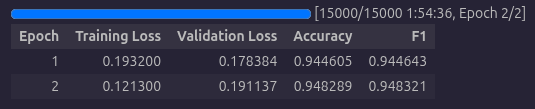

In [ ]:
model.save_pretrained("./model/saved_model")
tokenizer.save_pretrained("./model/saved_model")

## 4. Final Summary & Insights

### 📊 Performance Results
The model was trained for 2 epochs, achieving the following metrics on the test set:
* **Final Accuracy:** 94.8%.
* **Final F1-Score:** 0.948.

### 💡 Insights
* **Rapid Convergence:** The model reached over 94% accuracy in the first epoch, demonstrating the power of fine-tuning pre-trained transformer models.

* **Generalization:** The validation loss (0.1911) remained close to the training loss (0.1213), indicating that the model generalized well and did not severely overfit the training data.

* **Deployment:** The model and tokenizer have been saved and are ready for integration into the Streamlit application for live inference.